# Regresión y residuos: ajustar no es explicar causalmente

## Objetivo
Derivar mínimos cuadrados, inspeccionar residuos y observar sensibilidad a un dato extremo.

**Datos:** ejemplos analíticos o simulaciones didácticas; no representan clientes ni estimaciones de mercado.

## Preparación
Python 3.11 o posterior, NumPy, SciPy y Matplotlib. Todo se genera aquí; no necesita internet. Lee la fórmula y predice el resultado antes de ejecutar.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams.update({'figure.figsize': (8, 4.5), 'font.size': 11,
                     'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.prop_cycle': plt.cycler(color=['#285A8E','#C77C36','#687D45'])})
rng = np.random.default_rng(20261025)


## 1. Minimizar errores cuadrados

Para $y_i=a+bx_i+e_i$, minimizar $S=\sum e_i^2$ y anular derivadas produce $b=\sum(x_i-\bar x)(y_i-\bar y)/\sum(x_i-\bar x)^2$, $a=\bar y-b\bar x$, si el denominador es positivo. Usamos una relación sintética con ruido IID de media cero.

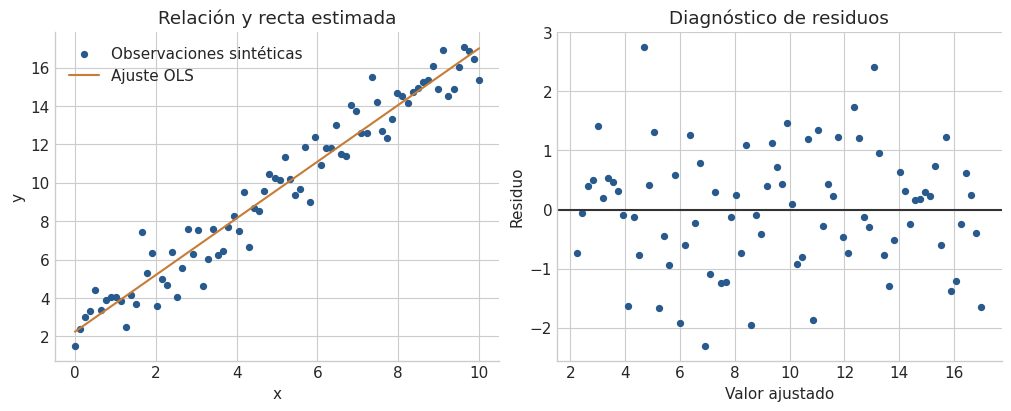

Intercepto y pendiente estimados: [2.25078512 1.47501044]


In [2]:
x=np.linspace(0,10,80)
y=2+1.5*x+rng.normal(0,1,len(x))
X=np.column_stack([np.ones_like(x),x])
coef=np.linalg.lstsq(X,y,rcond=None)[0]
pred=X@coef
residuos=y-pred
fig,axs=plt.subplots(1,2,figsize=(10,4),layout='constrained')
axs[0].scatter(x,y,s=18,label='Observaciones sintéticas')
axs[0].plot(x,pred,color='#C77C36',label='Ajuste OLS')
axs[0].set(xlabel='x',ylabel='y',title='Relación y recta estimada'); axs[0].legend()
axs[1].scatter(pred,residuos,s=18)
axs[1].axhline(0,color='#333333')
axs[1].set(xlabel='Valor ajustado',ylabel='Residuo',title='Diagnóstico de residuos'); plt.show()
print('Intercepto y pendiente estimados:',coef)

**Lectura del resultado.** Los coeficientes se aproximan a 2 y 1.5, pero una realización no los recupera exactamente. Un gráfico de residuos ayuda a detectar patrones; no demuestra que se cumplan todos los supuestos.

## 2. Un punto puede cambiar la recta

Añadimos un punto con x=30 e y=-20. Es un caso extremo construido para mostrar influencia. No se debe eliminar una observación solo porque cambia el resultado: hay que investigar su origen.

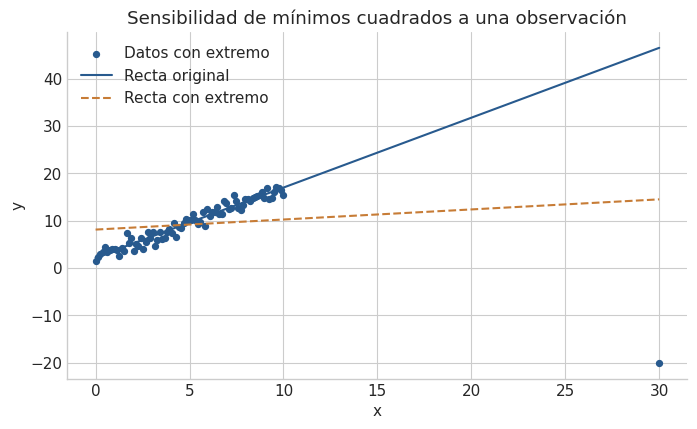

Cambio de pendiente: -1.2622745717797281


In [3]:
xx=np.append(x,30); yy=np.append(y,-20)
XX=np.column_stack([np.ones_like(xx),xx])
coef_extremo=np.linalg.lstsq(XX,yy,rcond=None)[0]
rejilla=np.linspace(0,30,100)
fig,ax=plt.subplots()
ax.scatter(xx,yy,s=18,label='Datos con extremo')
ax.plot(rejilla,coef[0]+coef[1]*rejilla,label='Recta original')
ax.plot(rejilla,coef_extremo[0]+coef_extremo[1]*rejilla,'--',label='Recta con extremo')
ax.set(xlabel='x',ylabel='y',title='Sensibilidad de mínimos cuadrados a una observación'); ax.legend(); plt.show()
print('Cambio de pendiente:',coef_extremo[1]-coef[1])

**Lectura del resultado.** El punto remoto tira de la recta. Ajustar una asociación no identifica causalidad: el experimento sintético conoce la generación, pero los datos reales requieren un diseño justificable.

## Practica antes de ver la solución

Ajusta x=(1,2,3), y=(2,3,5) con las fórmulas de medias. ¿Por qué la media de residuos es cero cuando hay intercepto?

In [4]:
# Escribe aquí tu razonamiento y tu cálculo.


## Solución razonada

La pendiente es 1.5 y el intercepto 1/3. La condición ∂S/∂a=−2Σeᵢ=0 fuerza residuos de suma cero; no es evidencia independiente de ausencia de sesgo.

## Comprobaciones

Estas pruebas contrastan identidades, referencias analíticas y tolerancias; no prueban teoremas ni validan modelos reales.

In [5]:
b_manual=((x-x.mean())*(y-y.mean())).sum()/((x-x.mean())**2).sum()
assert np.isclose(coef[1],b_manual)
assert np.allclose(X.T@residuos,0,atol=1e-9)
assert np.allclose(np.linalg.lstsq(np.array([[1,1],[1,2],[1,3]]),[2,3,5],rcond=None)[0],[1/3,1.5])
assert coef_extremo[1]<coef[1]
print('Fórmula, ecuaciones normales y sensibilidad: OK')

Fórmula, ecuaciones normales y sensibilidad: OK


## Siguiente paso

Cambia un parámetro, anticipa el efecto y explica por qué ocurre. Vuelve a ejecutar desde un kernel limpio. Consulta el índice del curso para la lección teórica relacionada.